# Solar Energy Data Cleaning : Olivia Pozytko


In [ ]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd

# STEP 1: Set file paths
data_file = Path("data/solar_raw.csv")
output_folder = Path("output")
output_folder.mkdir(exist_ok=True)

# STEP 2: Import solar data CSV
solar = pd.read_csv(data_file)

print("Original number of facilities:", len(solar))
print("Original columns:", solar.columns.tolist())

# STEP 3: Keep the important columns
columns = [
    "case_id",
    "p_name",
    "p_state",
    "p_county",
    "ylat",
    "xlong",
    "p_cap_ac", #Electrical Capacity \\ best to use to compare w/ transmission
    "p_cap_dc", #solar output 
    "p_year"
]

solar = solar[columns].copy()

# STEP 4: Rename columns
solar = solar.rename(columns={
    "case_id": "facility_id",
    "p_name": "facility_name",
    "p_state": "state",
    "p_county": "county",
    "ylat": "latitude",
    "xlong": "longitude",
    "p_cap_ac": "capacity_mw_ac",
    "p_cap_dc": "capacity_mw_dc",
    "p_year": "year"
})

# STEP 5: Remove duplicate facilities
solar = solar.drop_duplicates(subset="facility_id")

# STEP 6: Convert to numeric columns
numeric_cols = [
    "latitude",
    "longitude",
    "capacity_mw_ac",
    "capacity_mw_dc",
    "year"
]

for col in numeric_cols:
    solar[col] = pd.to_numeric(
        solar[col], errors="coerce"
    )

# STEP 7: Remove NA coordinates
solar = solar.dropna(
    subset=["latitude", "longitude"]
)

solar = solar[
    solar["latitude"].between(-90, 90) &
    solar["longitude"].between(-180, 180)
].copy()

# STEP 8: Filter to North Carolina
solar["state"] = solar["state"].str.strip().str.upper()
solar = solar[solar["state"] == "NC"].copy()

# STEP 9: Add source label
solar["energy_type"] = "solar"

# STEP 10: Create geographic points
solar_geo = gpd.GeoDataFrame(
    solar,
    geometry=gpd.points_from_xy(
        solar["longitude"],
        solar["latitude"]
    ),
    crs="EPSG:4326"
)

# STEP 11: Save cleaned files
solar.to_csv(
    output_folder / "solar_nc_clean.csv",
    index=False
)

solar_geo.to_file(
    output_folder / "solar_nc.geojson",
    driver="GeoJSON"
)

print("Cleaned NC solar facilities:", len(solar))
print("Files saved successfully!")


Original number of facilities: 6611
Original columns: ['case_id', 'multi_poly', 'eia_id', 'p_state', 'p_county', 'ylat', 'xlong', 'p_area', 'p_img_date', 'p_dig_conf', 'p_name', 'p_year', 'p_pwr_reg', 'p_tech_pri', 'p_tech_sec', 'p_sys_type', 'p_axis', 'p_azimuth', 'p_tilt', 'p_battery', 'p_cap_ac', 'p_cap_dc', 'p_type', 'p_agrivolt', 'p_comm', 'p_zscore']
Cleaned NC solar facilities: 760
Files saved successfully!


# Inspect the CSV is correctly cleaned using .head(), .shape, .isnull()

In [31]:
solar.head()

,facility_id,facility_name,state,county,latitude,longitude,capacity_mw_ac,capacity_mw_dc,year,energy_type
263,407366,Davidson III,NC,Davidson,35.7420,-80.2924,4.5,5.0,2010,solar
311,406473,Oak Solar,NC,Northampton,36.5361,-77.7661,120.0,201.0,2023,solar
314,400471,Haynes Farm,NC,Lincoln,35.5260,-81.2351,5.0,6.0,2013,solar
315,400725,Sonne One,NC,Wayne,35.4388,-77.8636,5.0,7.0,2016,solar
321,400464,Arndt Farm,NC,Catawba,35.7785,-81.1767,5.0,6.5,2012,solar


In [32]:
print(solar.shape)

(760, 10)


In [33]:
#Check for NA values
print(solar.isnull().sum())

facility_id       0
facility_name     0
state             0
county            0
latitude          0
longitude         0
capacity_mw_ac    0
capacity_mw_dc    0
year              0
energy_type       0
dtype: int64


In [34]:
#Find duplicates
print(solar.duplicated().sum())

0


In [35]:
#NC Solar
nc_solar = solar[solar["state"] == "NC"].copy()

print(nc_solar.shape)

(760, 10)


In [36]:
print(solar.columns.tolist())

['facility_id', 'facility_name', 'state', 'county', 'latitude', 'longitude', 'capacity_mw_ac', 'capacity_mw_dc', 'year', 'energy_type']


In [37]:
print(nc_solar["capacity_mw_ac"].describe())

count    760.000000
mean       8.812237
std       15.597338
min        0.900000
25%        3.600000
50%        5.000000
75%        5.000000
max      120.000000
Name: capacity_mw_ac, dtype: float64


In [38]:
print((nc_solar["capacity_mw_ac"] >= 5).sum())

443


In [39]:
nc_solar.to_csv("solar_nc_clean.csv", index=False)

# Convert Solar Data to Geographic Points using GeoPandas


In [40]:
solar_gdf = gpd.GeoDataFrame(
    nc_solar,
    geometry=gpd.points_from_xy(
        nc_solar["longitude"],
        nc_solar["latitude"]
    ),
    crs="EPSG:4326"
)

In [41]:
print(solar_gdf.head())

     facility_id facility_name state       county  latitude  longitude  \
263       407366  Davidson III    NC     Davidson   35.7420   -80.2924   
311       406473     Oak Solar    NC  Northampton   36.5361   -77.7661   
314       400471   Haynes Farm    NC      Lincoln   35.5260   -81.2351   
315       400725     Sonne One    NC        Wayne   35.4388   -77.8636   
321       400464    Arndt Farm    NC      Catawba   35.7785   -81.1767   

     capacity_mw_ac  capacity_mw_dc  year energy_type  \
263             4.5             5.0  2010       solar   
311           120.0           201.0  2023       solar   
314             5.0             6.0  2013       solar   
315             5.0             7.0  2016       solar   
321             5.0             6.5  2012       solar   

                     geometry  
263   POINT (-80.2924 35.742)  
311  POINT (-77.7661 36.5361)  
314   POINT (-81.2351 35.526)  
315  POINT (-77.8636 35.4388)  
321  POINT (-81.1767 35.7785)  


In [42]:
print(solar_gdf.crs)

EPSG:4326


In [43]:
solar_gdf = solar_gdf.to_crs(epsg=32119)
#Transmission Lines are beneficial to see in meters rather than degrees

In [44]:
print(solar_gdf.crs)
print(solar_gdf.head())

EPSG:32119
     facility_id facility_name state       county  latitude  longitude  \
263       407366  Davidson III    NC     Davidson   35.7420   -80.2924   
311       406473     Oak Solar    NC  Northampton   36.5361   -77.7661   
314       400471   Haynes Farm    NC      Lincoln   35.5260   -81.2351   
315       400725     Sonne One    NC        Wayne   35.4388   -77.8636   
321       400464    Arndt Farm    NC      Catawba   35.7785   -81.1767   

     capacity_mw_ac  capacity_mw_dc  year energy_type  \
263             4.5             5.0  2010       solar   
311           120.0           201.0  2023       solar   
314             5.0             6.0  2013       solar   
315             5.0             7.0  2016       solar   
321             5.0             6.5  2012       solar   

                          geometry  
263  POINT (492709.228 221736.782)  
311  POINT (720107.207 309777.287)  
314  POINT (406917.966 199294.524)  
315  POINT (712769.396 187929.568)  
321  POINT (4128

In [45]:
solar_gdf.to_file("solar_nc.geojson", driver="GeoJSON")

# Create A Map of Solar Facilities in the US

In [49]:

# Load US state boundaries
states = gpd.read_file(
    "data/state_boundaries.zip"
)

nc_boundary = states[states["STUSPS"] == "NC"].copy()

nc_boundary = nc_boundary.to_crs(solar_gdf.crs)

print(nc_boundary.head())


  STATEFP   STATENS      GEOIDFQ GEOID STUSPS            NAME LSAD  \
5      37  01027616  0400000US37    37     NC  North Carolina   00   

          ALAND       AWATER  \
5  125935547374  13453873497   

                                            geometry  
5  MULTIPOLYGON (((904893.097 247351.126, 905649....  


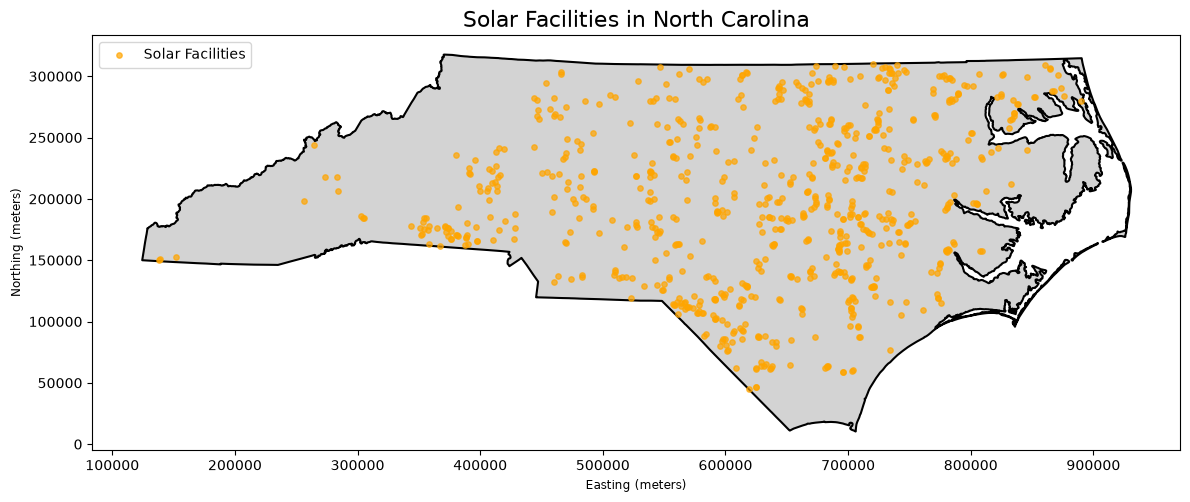

In [50]:

fig, ax = plt.subplots(figsize=(12, 8))

#  North Carolina boundary
nc_boundary.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=1.5
)

# solar facilities
solar_gdf.plot(
    ax=ax,
    color="orange",
    markersize=15,
    alpha=0.7,
    label="Solar Facilities"
)

ax.set_title(
    "Solar Facilities in North Carolina",
    fontsize=16
)

ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

ax.legend()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()


In [51]:
plt.savefig(
    "solar_nc_map.png",
    dpi=300,
    bbox_inches="tight"
)
#saved

<Figure size 640x480 with 0 Axes>